# GoSmart DS — DICOM Knowledge Graph & Vector Search Playground

Interactive playground for exploring the ingested **DICOM Standard Knowledge Graph** in Neo4j and testing **semantic vector search** powered by `ollama/embeddinggemma-2:270m` (768-dim L2-normalized vectors) via GoSmart DS's dynamic `LLM_Config` backbone.

**What we explore in this notebook:**
1. Platform bootstrap verification (`:System` → `GoSmart Health` `:Group` → `:LLM_Config`)
2. Live graph inventory & visual breakdown of DICOM nodes, relationships, and `:Embedding` coverage
3. Semantic vector search over `embedding_vector_idx` (`NAME` & `DESCRIPTION` aspects)
4. Multi-hop DICOM graph traversal (`DicomSOPClass` → `DicomCIOD` → `DicomModule` → `DicomElement` → `DicomConfidentialityProfile`) + Lucene full-text comparison

## 1. Connect to Neo4j & Resolve Active `LLM_Config`

Load GoSmart DS settings from `.env`, verify Neo4j connectivity, and inspect the bootstrapped `GoSmart Health` LLM configurations (`embedding-v1` and `inference-v1`).

In [1]:
from typing import Any, Optional

import matplotlib.pyplot as plt
import pandas as pd

from gosmart_dictionary_service.core.config import get_settings
from gosmart_dictionary_service.db.neo4j import Neo4jClient
from gosmart_dictionary_service.model.llm_config import (
    DEFAULT_EMBEDDING_CONFIG_TAG,
    DEFAULT_INFERENCE_CONFIG_TAG,
)
from gosmart_dictionary_service.service.embedding_service import EmbeddingService
from gosmart_dictionary_service.service.llm_config_service import LLMConfigService
from gosmart_dictionary_service.service.system_service import DEFAULT_GROUP_CODE

pd.set_option("display.max_colwidth", 100)
pd.set_option("display.width", 140)

settings = get_settings()
client = Neo4jClient(settings=settings)
driver = client.get_sync_driver()
driver.verify_connectivity()

llm_config_service = LLMConfigService(client=client)
embedding_service = EmbeddingService(client=client, llm_config_service=llm_config_service, settings=settings)

embed_cfg = llm_config_service.get_llm_config_by_tag_sync(
    DEFAULT_EMBEDDING_CONFIG_TAG,
    group_code=DEFAULT_GROUP_CODE,
)
infer_cfg = llm_config_service.get_llm_config_by_tag_sync(
    DEFAULT_INFERENCE_CONFIG_TAG,
    group_code=DEFAULT_GROUP_CODE,
)


def cypher_df(query: str, params: Optional[dict[str, Any]] = None) -> pd.DataFrame:
    """Execute a read-only Cypher query against the configured Neo4j database and return a DataFrame."""
    with driver.session(database=settings.DB_DATABASE) as session:
        rows = [record.data() for record in session.run(query, params or {})]
    return pd.DataFrame(rows)


print(f"Connected to Neo4j: {settings.DB_CONNECTION_URI} (db={settings.DB_DATABASE})")
print(f"Embedding config  : tag={embed_cfg.tag!r}, provider={embed_cfg.provider}, model={embed_cfg.model}, dims={embed_cfg.dimensions}, url={embed_cfg.url}")
print(f"Inference config  : tag={infer_cfg.tag!r}, provider={infer_cfg.provider}, model={infer_cfg.model}, url={infer_cfg.url}")

Connected to Neo4j: bolt://manabusb3.local.:7688 (db=neo4j)
Embedding config  : tag='embedding-v1', provider=ollama, model=embeddinggemma-2:270m, dims=768, url=http://m5.local.:11434
Inference config  : tag='inference-v1', provider=ollama, model=gemma4:e2b, url=http://manabusb3.local.:11434


## 2. Production DICOM Graph Inventory & Embedding Coverage

Inspect live node counts, `:Embedding` coverage (`NAME` vs `DESCRIPTION`), and relationship totals across the production dictionary (`test_id IS NULL`).

In [3]:
node_inventory_df = cypher_df(
    """
    UNWIND [
        'DicomElement', 'DicomCIOD', 'DicomModule', 'DicomMacro',
        'DicomSOPClass', 'DicomConfidentialityProfile', 'DicomStandardReference'
    ] AS lbl
    CALL (lbl) {
        MATCH (n)
        WHERE lbl IN labels(n) AND n.test_id IS NULL
        OPTIONAL MATCH (e:Embedding)-[r:EMBEDS]->(n)
        WHERE e.test_id IS NULL
        RETURN count(DISTINCT n) AS node_count,
               count(DISTINCT CASE WHEN r.aspect = 'NAME' THEN e END) AS name_embeddings,
               count(DISTINCT CASE WHEN r.aspect = 'DESCRIPTION' THEN e END) AS desc_embeddings
    }
    RETURN lbl AS label, node_count, name_embeddings, desc_embeddings,
           (name_embeddings + desc_embeddings) AS total_embeddings
    ORDER BY node_count DESC
    """
)

rel_inventory_df = cypher_df(
    """
    UNWIND [
        'IMPLEMENTS_CIOD', 'HAS_MODULE', 'HAS_FUNC_GROUP_MACRO',
        'USES_ELEMENT', 'HAS_CONFIDENTIALITY_PROFILE', 'REFERENCES_STANDARD', 'EMBEDS'
    ] AS rtype
    CALL (rtype) {
        MATCH ()-[r]->()
        WHERE type(r) = rtype AND r.test_id IS NULL
        RETURN count(r) AS rel_count
    }
    RETURN rtype AS relationship_type, rel_count
    ORDER BY rel_count DESC
    """
)

print(f"Total DICOM nodes     : {node_inventory_df['node_count'].sum():,}")
print(f"Total DICOM embeddings: {node_inventory_df['total_embeddings'].sum():,}")
print(f"Total relationships   : {rel_inventory_df['rel_count'].sum():,}")
display(node_inventory_df)
display(rel_inventory_df)

Total DICOM nodes     : 7,843
Total DICOM embeddings: 7,726
Total relationships   : 130,783


,label,node_count,name_embeddings,desc_embeddings,total_embeddings
0,DicomElement,5129,5123,0,5123
1,DicomStandardReference,1014,0,0,0
2,DicomConfidentialityProfile,621,621,0,621
3,DicomModule,435,435,435,870
4,DicomMacro,298,298,298,596
5,DicomSOPClass,175,175,0,175
6,DicomCIOD,171,171,170,341


,relationship_type,rel_count
0,USES_ELEMENT,111685
1,EMBEDS,7726
2,REFERENCES_STANDARD,6858
3,HAS_MODULE,3258
4,HAS_CONFIDENTIALITY_PROFILE,617
5,HAS_FUNC_GROUP_MACRO,464
6,IMPLEMENTS_CIOD,175


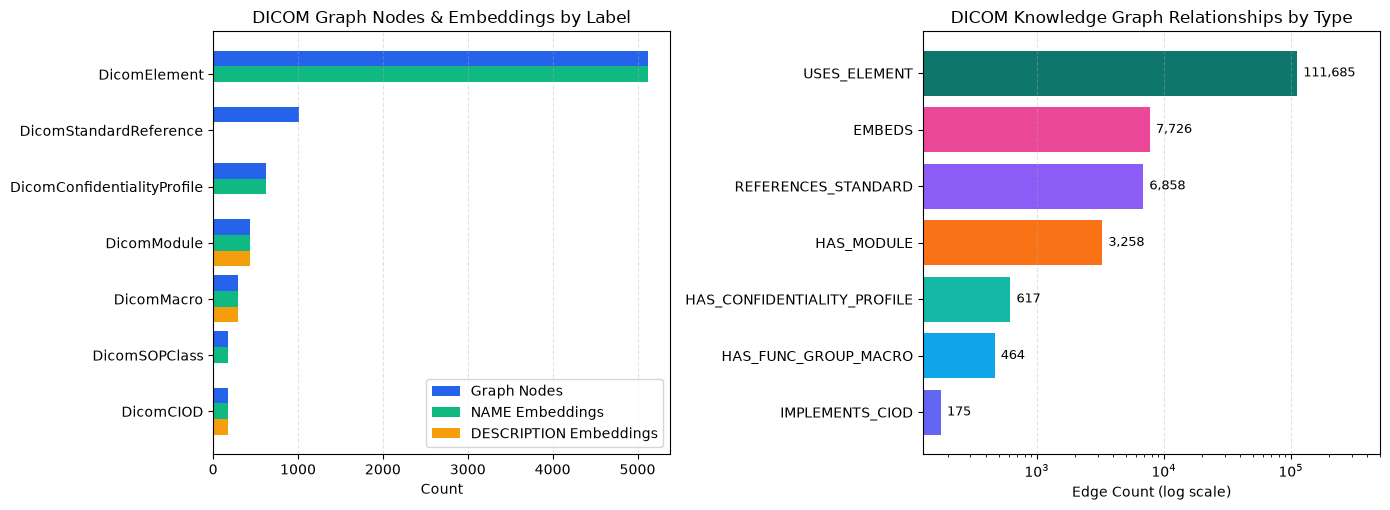

In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.2))

# Left: Nodes vs NAME & DESCRIPTION Embeddings by Label
inv = node_inventory_df.sort_values("node_count", ascending=True)
y = range(len(inv))
bar_h = 0.28
ax1.barh([i + bar_h for i in y], inv["node_count"], height=bar_h, label="Graph Nodes", color="#2563eb")
ax1.barh(list(y), inv["name_embeddings"], height=bar_h, label="NAME Embeddings", color="#10b981")
ax1.barh([i - bar_h for i in y], inv["desc_embeddings"], height=bar_h, label="DESCRIPTION Embeddings", color="#f59e0b")
ax1.set_yticks(list(y))
ax1.set_yticklabels(inv["label"])
ax1.set_xlabel("Count")
ax1.set_title("DICOM Graph Nodes & Embeddings by Label")
ax1.legend(loc="lower right", frameon=True)
ax1.grid(axis="x", linestyle="--", alpha=0.35)

# Right: Relationships by Type (log scale to show 175 alongside 111,685 cleanly)
rels = rel_inventory_df.sort_values("rel_count", ascending=True)
colors = ["#6366f1", "#0ea5e9", "#14b8a6", "#f97316", "#8b5cf6", "#ec4899", "#0f766e"]
bars = ax2.barh(rels["relationship_type"], rels["rel_count"], color=colors[: len(rels)])
ax2.set_xscale("log")
ax2.set_xlabel("Edge Count (log scale)")
ax2.set_title("DICOM Knowledge Graph Relationships by Type")
ax2.grid(axis="x", linestyle="--", alpha=0.35)
for bar, cnt in zip(bars, rels["rel_count"]):
    ax2.text(cnt * 1.12, bar.get_y() + bar.get_height() / 2, f"{cnt:,}", va="center", fontsize=9)
ax2.set_xlim(right=rels["rel_count"].max() * 4.5)

plt.tight_layout()
plt.show()

## 3. Semantic Vector Search Playground (`embedding_vector_idx`)

Embed natural-language clinical/imaging queries on the fly via `EmbeddingService` (`ollama/embeddinggemma-2:270m`, 768 dims) and retrieve top cosine-similarity matches from Neo4j's vector index `embedding_vector_idx`.

In [27]:
async def semantic_search(
    query_text: str,
    *,
    top_k: int = 8,
    labels: Optional[list[str]] = None,
    aspect: Optional[str] = None,
) -> pd.DataFrame:
    """Embed ``query_text`` with the active ``embedding-v1`` config and search ``embedding_vector_idx``."""
    vectors = await embedding_service.compute_vectors([query_text], embed_cfg)
    query_vec = vectors[0]
    fetch_k = max(top_k * 5, 40)

    return cypher_df(
        """
        CALL db.index.vector.queryNodes('embedding_vector_idx', $fetch_k, $query_vec)
        YIELD node AS emb, score
        WHERE emb.test_id IS NULL
          AND emb.modelTag = $model_tag
          AND ($aspect IS NULL OR emb.targetFieldTag = $aspect)
        MATCH (emb)-[r:EMBEDS]->(target)
        WHERE target.test_id IS NULL
          AND ($labels IS NULL OR any(lbl IN labels(target) WHERE lbl IN $labels))
        RETURN round(score, 4) AS cosine_score,
               head(labels(target)) AS label,
               r.aspect AS aspect,
               coalesce(target.tag, target.sop_class_uid, target.ciod_id, target.module_id, target.macro_id) AS code,
               target.name AS name,
               left(emb.text, 120) AS embedded_text
        ORDER BY cosine_score DESC
        LIMIT $top_k
        """,
        {
            "fetch_k": fetch_k,
            "query_vec": query_vec,
            "model_tag": embed_cfg.tag,
            "aspect": aspect,
            "labels": labels,
            "top_k": top_k,
        },
    )


sample_queries = [
    "white cell count",
    "patient's comments"
    "radiation dose and CT exposure parameters",
    "patient de-identification birth date and PHI removal",
    "slice thickness and physical pixel spacing",
]

for q in sample_queries:
    print()
    print(f"=== Query: {q!r} ===")
    display(await semantic_search(q, top_k=6))

Received notification from DBMS server: <GqlStatusObject gql_status='01N01', status_description='warn: feature deprecated with replacement. db.index.vector.queryNodes is deprecated. It is replaced by SEARCH.', position=<SummaryInputPosition line=2, column=9, offset=9>, raw_classification='DEPRECATION', classification=<NotificationClassification.DEPRECATION: 'DEPRECATION'>, raw_severity='WARNING', severity=<NotificationSeverity.WARNING: 'WARNING'>, diagnostic_record={'_classification': 'DEPRECATION', '_severity': 'WARNING', '_position': {'offset': 9, 'line': 2, 'column': 9}, 'OPERATION': '', 'OPERATION_CODE': '0', 'CURRENT_SCHEMA': '/'}> for query: "\n        CALL db.index.vector.queryNodes('embedding_vector_idx', $fetch_k, $query_vec)\n        YIELD node AS emb, score\n        WHERE emb.test_id IS NULL\n          AND emb.modelTag = $model_tag\n          AND ($aspect IS NULL OR emb.targetFieldTag = $aspect)\n        MATCH (emb)-[r:EMBEDS]->(target)\n        WHERE target.test_id IS NULL\


=== Query: 'white cell count' ===


,cosine_score,label,aspect,code,name,embedded_text
0,0.8414,DicomMacro,DESCRIPTION,ophthalmic-patient-clinical-information-and-test-lens-parameters,Ophthalmic Patient Clinical Information and Test Lens Parameters,DICOM Macro Ophthalmic Patient Clinical Information and Test Lens Parameters: This macro specifi...
1,0.8390,DicomElement,NAME,"(0018,1243)",Count Rate,"DICOM Element (0018,1243) CountRate: Count Rate"
2,0.8384,DicomModule,DESCRIPTION,ophthalmic-patient-clinical-information-and-test-lens-parameters,Ophthalmic Patient Clinical Information and Test Lens Parameters,DICOM Module Ophthalmic Patient Clinical Information and Test Lens Parameters: This module defin...
3,0.8377,DicomElement,NAME,"(0016,0043)",White Balance,"DICOM Element (0016,0043) WhiteBalance: White Balance"
4,0.8365,DicomElement,NAME,"(0024,0060)",False Positives Quantity,"DICOM Element (0024,0060) FalsePositivesQuantity: False Positives Quantity"
5,0.8328,DicomElement,NAME,"(0024,0056)",Positive Catch Trials Quantity,"DICOM Element (0024,0056) PositiveCatchTrialsQuantity: Positive Catch Trials Quantity"


Received notification from DBMS server: <GqlStatusObject gql_status='01N01', status_description='warn: feature deprecated with replacement. db.index.vector.queryNodes is deprecated. It is replaced by SEARCH.', position=<SummaryInputPosition line=2, column=9, offset=9>, raw_classification='DEPRECATION', classification=<NotificationClassification.DEPRECATION: 'DEPRECATION'>, raw_severity='WARNING', severity=<NotificationSeverity.WARNING: 'WARNING'>, diagnostic_record={'_classification': 'DEPRECATION', '_severity': 'WARNING', '_position': {'offset': 9, 'line': 2, 'column': 9}, 'OPERATION': '', 'OPERATION_CODE': '0', 'CURRENT_SCHEMA': '/'}> for query: "\n        CALL db.index.vector.queryNodes('embedding_vector_idx', $fetch_k, $query_vec)\n        YIELD node AS emb, score\n        WHERE emb.test_id IS NULL\n          AND emb.modelTag = $model_tag\n          AND ($aspect IS NULL OR emb.targetFieldTag = $aspect)\n        MATCH (emb)-[r:EMBEDS]->(target)\n        WHERE target.test_id IS NULL\


=== Query: "patient's commentsradiation dose and CT exposure parameters" ===


,cosine_score,label,aspect,code,name,embedded_text
0,0.9163,DicomConfidentialityProfile,NAME,"(0040,0310)",Comments on Radiation Dose,"DICOM Confidentiality Profile (0040,0310) (Basic=X): Comments on Radiation Dose"
1,0.9114,DicomElement,NAME,"(0040,0310)",Comments on Radiation Dose,"DICOM Element (0040,0310) CommentsOnRadiationDose: Comments on Radiation Dose"
2,0.9097,DicomMacro,NAME,radiobiological-dose-effect-description,Radiobiological Dose Effect Description,DICOM Macro: Radiobiological Dose Effect Description
3,0.9069,DicomConfidentialityProfile,NAME,"(0010,4000)",Patient Comments,"DICOM Confidentiality Profile (0010,4000) (Basic=X): Patient Comments"
4,0.9067,DicomElement,NAME,"(0010,4000)",Patient Comments,"DICOM Element (0010,4000) PatientComments: Patient Comments"
5,0.9044,DicomConfidentialityProfile,NAME,"(3010,0061)",Prior Treatment Dose Description,"DICOM Confidentiality Profile (3010,0061) (Basic=X): Prior Treatment Dose Description"


... (2 outputs left out)

,cosine_score,label,aspect,code,name,embedded_text
0,0.9078,DicomConfidentialityProfile,NAME,"(0010,0030)",Patient's Birth Date,"DICOM Confidentiality Profile (0010,0030) (Basic=Z): Patient's Birth Date"
1,0.9034,DicomConfidentialityProfile,NAME,"(0008,1052)",Performing Physician Identification Sequence,"DICOM Confidentiality Profile (0008,1052) (Basic=X): Performing Physician Identification Sequence"
2,0.9030,DicomConfidentialityProfile,NAME,"(0010,0032)",Patient's Birth Time,"DICOM Confidentiality Profile (0010,0032) (Basic=X): Patient's Birth Time"
3,0.8999,DicomConfidentialityProfile,NAME,"(0010,1005)",Patient's Birth Name,"DICOM Confidentiality Profile (0010,1005) (Basic=X): Patient's Birth Name"
4,0.8996,DicomElement,NAME,"(0010,0032)",Patient's Birth Time,"DICOM Element (0010,0032) PatientBirthTime: Patient's Birth Time"
5,0.8989,DicomMacro,NAME,issuer-of-patient-id,Issuer of Patient ID,DICOM Macro: Issuer of Patient ID


Received notification from DBMS server: <GqlStatusObject gql_status='01N01', status_description='warn: feature deprecated with replacement. db.index.vector.queryNodes is deprecated. It is replaced by SEARCH.', position=<SummaryInputPosition line=2, column=9, offset=9>, raw_classification='DEPRECATION', classification=<NotificationClassification.DEPRECATION: 'DEPRECATION'>, raw_severity='WARNING', severity=<NotificationSeverity.WARNING: 'WARNING'>, diagnostic_record={'_classification': 'DEPRECATION', '_severity': 'WARNING', '_position': {'offset': 9, 'line': 2, 'column': 9}, 'OPERATION': '', 'OPERATION_CODE': '0', 'CURRENT_SCHEMA': '/'}> for query: "\n        CALL db.index.vector.queryNodes('embedding_vector_idx', $fetch_k, $query_vec)\n        YIELD node AS emb, score\n        WHERE emb.test_id IS NULL\n          AND emb.modelTag = $model_tag\n          AND ($aspect IS NULL OR emb.targetFieldTag = $aspect)\n        MATCH (emb)-[r:EMBEDS]->(target)\n        WHERE target.test_id IS NULL\


=== Query: 'slice thickness and physical pixel spacing' ===


,cosine_score,label,aspect,code,name,embedded_text
0,0.8915,DicomMacro,NAME,pixel-measures,Pixel Measures,DICOM Macro: Pixel Measures
1,0.8901,DicomMacro,NAME,basic-pixel-spacing-calibration,Basic Pixel Spacing Calibration,DICOM Macro: Basic Pixel Spacing Calibration
2,0.8876,DicomElement,NAME,"(0018,0088)",Spacing Between Slices,"DICOM Element (0018,0088) SpacingBetweenSlices: Spacing Between Slices"
3,0.8871,DicomElement,NAME,"(0018,0050)",Slice Thickness,"DICOM Element (0018,0050) SliceThickness: Slice Thickness"
4,0.8845,DicomElement,NAME,"(0028,0030)",Pixel Spacing,"DICOM Element (0028,0030) PixelSpacing: Pixel Spacing"
5,0.8832,DicomMacro,NAME,x-ray-object-thickness,X-Ray Object Thickness,DICOM Macro: X-Ray Object Thickness


## 4. Multi-Hop Graph Traversal & Full-Text Search (`CT Image` + PS3.15 Confidentiality)

Traverse `(:DicomSOPClass)-[:IMPLEMENTS_CIOD]->(:DicomCIOD)-[:HAS_MODULE]->(:DicomModule)-[:USES_ELEMENT]->(:DicomElement)-[:HAS_CONFIDENTIALITY_PROFILE]->(:DicomConfidentialityProfile)` to inspect de-identification rules for a specific SOP Class, and compare with Neo4j Lucene full-text search (`dicom_element_fulltext_idx`).

In [8]:
ct_phi_df = cypher_df(
    """
    MATCH (sop:DicomSOPClass {sop_class_uid: '1.2.840.10008.5.1.4.1.1.2'})
          -[:IMPLEMENTS_CIOD]->(ciod:DicomCIOD)
          -[hm:HAS_MODULE]->(m:DicomModule)
          -[ue:USES_ELEMENT]->(e:DicomElement)
          -[:HAS_CONFIDENTIALITY_PROFILE]->(cp:DicomConfidentialityProfile)
    WHERE sop.test_id IS NULL AND ciod.test_id IS NULL AND m.test_id IS NULL
      AND e.test_id IS NULL AND cp.test_id IS NULL
      AND hm.usage = 'M'
      AND m.name IN ['Patient', 'General Study', 'General Series', 'CT Image']
      AND size(split(ue.path, ':')) = 2
    RETURN m.name AS module,
           e.tag AS tag,
           e.keyword AS keyword,
           e.vr AS vr,
           ue.requirement_type AS req_type,
           cp.basic_profile AS basic_deid_action,
           cp.rtn_uids_opt AS retain_uids,
           cp.rtn_long_full_dates_opt AS retain_full_dates
    ORDER BY module, tag
    LIMIT 25
    """
)

print("CT Image Storage (1.2.840.10008.5.1.4.1.1.2) — Top-Level Mandatory-Module PHI / PS3.15 Rules:")
display(ct_phi_df)

fulltext_df = cypher_df(
    """
    CALL db.index.fulltext.queryNodes('dicom_element_fulltext_idx', 'SliceThickness OR PixelSpacing')
    YIELD node AS e, score
    WHERE e.test_id IS NULL
    RETURN round(score, 4) AS lucene_score,
           e.tag AS tag,
           e.keyword AS keyword,
           e.name AS name,
           e.vr AS vr,
           e.vm AS vm,
           e.is_retired AS retired
    ORDER BY lucene_score DESC
    LIMIT 10
    """
)

print("Lucene Full-Text Index (dicom_element_fulltext_idx) Results:")
display(fulltext_df)

CT Image Storage (1.2.840.10008.5.1.4.1.1.2) — Top-Level Mandatory-Module PHI / PS3.15 Rules:


,module,tag,keyword,vr,req_type,basic_deid_action,retain_uids,retain_full_dates
0,General Series,"(0008,0021)",SeriesDate,DA,3,X/D,NaN,K
1,General Series,"(0008,0031)",SeriesTime,TM,3,X/D,NaN,K
2,General Series,"(0008,103E)",SeriesDescription,LO,3,X,NaN,NaN
3,General Series,"(0008,1050)",PerformingPhysicianName,PN,3,X,NaN,NaN
4,General Series,"(0008,1052)",PerformingPhysicianIdentificationSequence,SQ,3,X,NaN,NaN
5,General Series,"(0008,1070)",OperatorsName,PN,3,X/Z/D,NaN,NaN
6,General Series,"(0008,1072)",OperatorIdentificationSequence,SQ,3,X/D,NaN,NaN
7,General Series,"(0008,1111)",ReferencedPerformedProcedureStepSequence,SQ,3,X/Z/D,K,NaN
8,General Series,"(0018,1030)",ProtocolName,LO,3,X/D,NaN,NaN
9,General Series,"(0020,000E)",SeriesInstanceUID,UI,1,U,K,NaN


Lucene Full-Text Index (dicom_element_fulltext_idx) Results:


,lucene_score,tag,keyword,name,vr,vm,retired
0,3.6985,"(0028,0030)",PixelSpacing,Pixel Spacing,DS,2,False
1,3.4663,"(0018,0050)",SliceThickness,Slice Thickness,DS,1,False


## Summary

### Data Analysis Key Findings
* **Active System & LLM Configuration:** The Neo4j graph (`neo4j`) is bootstrapped with the top-level `GoSmart Health` group and active `LLM_Config` bindings pointing `embedding-v1` to `ollama/embeddinggemma-2:270m` (768 dimensions) and `inference-v1` to `ollama/gemma4:e2b`.
* **Production DICOM Graph Inventory:** Full DICOM standard ingestion populated **7,843** production nodes (`5,129` `DicomElement`, `1,014` `DicomStandardReference`, `621` `DicomConfidentialityProfile`, `435` `DicomModule`, `298` `DicomMacro`, `175` `DicomSOPClass`, and `171` `DicomCIOD`) connected by **130,783** relationships (`111,685` `USES_ELEMENT`, `7,726` `EMBEDS`, `6,858` `REFERENCES_STANDARD`, `3,258` `HAS_MODULE`, `617` `HAS_CONFIDENTIALITY_PROFILE`, `464` `HAS_FUNC_GROUP_MACRO`, and `175` `IMPLEMENTS_CIOD`).
* **Vector Embedding Coverage:** **7,726** decoupled 768-dimensional L2-normalized `:Embedding` nodes (`embedding-v1`) are linked via `[:EMBEDS]` across all `NAME` and `DESCRIPTION` text fields (`5,123` `DicomElement`, `870` `DicomModule`, `621` `DicomConfidentialityProfile`, `596` `DicomMacro`, `341` `DicomCIOD`, and `175` `DicomSOPClass`).
* **Semantic Search Verification:** Cosine similarity queries against `embedding_vector_idx` surfaced accurate domain matches across natural-language prompts—for example, `"slice thickness and physical pixel spacing"` retrieved `Basic Pixel Spacing Calibration` (score `0.8901`), `(0018,0088) Spacing Between Slices` (`0.8876`), `(0018,0050) Slice Thickness` (`0.8871`), and `(0028,0030) Pixel Spacing` (`0.8845`).
* **Multi-Hop Graph Traversal & Full-Text Search:** Traversing `DicomSOPClass` (`CT Image Storage`, `1.2.840.10008.5.1.4.1.1.2`) through `IMPLEMENTS_CIOD -> HAS_MODULE -> USES_ELEMENT -> HAS_CONFIDENTIALITY_PROFILE` returned **25** top-level mandatory-module PHI/PS3.15 de-identification rules (such as `(0008,0021) SeriesDate` with `X/D` basic action and `K` retain-full-dates option), while `dicom_element_fulltext_idx` matched `(0028,0030) PixelSpacing` (Lucene score `3.6985`) and `(0018,0050) SliceThickness` (`3.4663`).

### Insights or Next Steps
* **Hybrid Retrieval APIs & MCP Tools:** Combine `embedding_vector_idx` semantic search, `dicom_element_fulltext_idx` lexical search, and multi-hop Cypher traversals into FastAPI endpoints and MCP tools for automated DICOM lookup, conformance validation, and de-identification profile planning.
* **Cypher Syntax Modernization:** Neo4j flagged `db.index.vector.queryNodes` as deprecated in favor of the newer `SEARCH` clause; future service query builders can adopt `SEARCH` syntax when targeting Neo4j 5.26+ / 2025+.
* **Wildcard Confidentiality Matching:** Four PS3.15 confidentiality profiles (`621` nodes vs. `617` `HAS_CONFIDENTIALITY_PROFILE` edges) use repeating-group wildcard tags (e.g., `(50xx,xxxx)`, `(60xx,xxxx)`) that intentionally do not map 1:1 to a single concrete `DicomElement`; downstream de-identification logic can evaluate those wildcard patterns directly at runtime.